# transistor回転拡張：edge補完と反射補完を比較する
2026-11-05。画像端の黒い丸が伸びる現象を確認し、補完方法だけを変えて見比べます。

- **edge**：端の画素を外側へ延長する。黒い丸が画像端にあると帯状に伸びることがある。
- **reflect**：画像端の内側を鏡写しにして補う。引き伸ばしを避けられる一方、模様や対象の一部が複製・折り返しされることがある。

画像全体1024×1024 → 周囲を補完 → 最近傍で回転 → 中央1024×1024 → LANCZOSで128×128 → 白黒、を共通にします。0度は補完・回転せず元画像を使います。

**画像加工の比較だけを行います。学習・モデル推論・AUROC評価は実行せず、既存の学習ノートブックも変更しません。見た目の自然さと異常検知性能の向上は別の確認事項です。**

In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib,math,json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle,Patch
from matplotlib.colors import ListedColormap
from IPython.display import display

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents) if (p/'memory/memory.md').is_file() and (p/'data/transistor').is_dir()),None)
if ROOT is None:raise FileNotFoundError('リポジトリ内を作業ディレクトリにしてください。')
TRAIN_DIR=ROOT/'data/transistor/train/good'
PRIMARY_IMAGE='000.png'
SAMPLE_IMAGES=['000.png','001.png','002.png']  # 他の正常画像へ変更できます。
ANGLES=tuple(range(0,360,36))
COMPARE_ANGLES=(36,72,144)
MULTI_ANGLES=(36,72)
MODES=('edge','reflect')
LABELS={'edge':'edge：端を延長','reflect':'reflect：鏡写し'}
ZOOM_BOX=(0,0,360,360)  # 回転後の1024画像上の(x0,y0,x1,y1)。同じ領域を両方法で拡大。
np.random.seed(42)
fonts={f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({'font.family':next((f for f in ['Meiryo','Yu Gothic','Noto Sans CJK JP'] if f in fonts),'DejaVu Sans'),
                     'font.size':12,'axes.unicode_minus':False,'figure.dpi':100,'figure.facecolor':'white'})
source_names=list(dict.fromkeys([PRIMARY_IMAGE,*SAMPLE_IMAGES]))
images={};source_hashes={}
for name in source_names:
    path=TRAIN_DIR/name
    if Path(name).name!=name:raise ValueError('画像名はtrain/good内のファイル名のみ指定してください。')
    source_hashes[name]=hashlib.sha256(path.read_bytes()).hexdigest()
    with Image.open(path) as im:images[name]=im.convert('RGB').copy()
    if images[name].size!=(1024,1024):raise ValueError(f'想定外の画像サイズ：{name} {images[name].size}')
x0,y0,x1,y1=ZOOM_BOX
assert 0<=x0<x1<=1024 and 0<=y0<y1<=1024

def edge_pad_width(size):return math.ceil((math.hypot(*size)-min(size))/2)+4

@lru_cache(maxsize=64)
def rotated(name,angle,mode):
    if mode not in MODES:raise ValueError(mode)
    image=images[name];width,height=image.size
    if angle==0:return image.copy(),np.ones((height,width),dtype=bool)
    pad=edge_pad_width(image.size)
    extended=Image.fromarray(np.pad(np.asarray(image),((pad,pad),(pad,pad),(0,0)),mode=mode))
    crop=(pad,pad,pad+width,pad+height)
    result=np.asarray(extended.rotate(angle,resample=Image.Resampling.NEAREST,expand=False,fillcolor=(255,255,255)).crop(crop)).copy()
    support=Image.new('L',extended.size,255).rotate(angle,resample=Image.Resampling.NEAREST,expand=False,fillcolor=0).crop(crop)
    assert np.all(np.asarray(support)==255),'補完幅が不足しています。'
    original_mask=np.asarray(Image.new('L',image.size,255).rotate(angle,resample=Image.Resampling.NEAREST,expand=False,fillcolor=0))>0
    original_part=np.asarray(image.rotate(angle,resample=Image.Resampling.NEAREST,expand=False,fillcolor=(255,255,255)))
    # 現在の学習用コードと同じく、元画像由来の画素を厳密に維持する。
    result[original_mask]=original_part[original_mask]
    return Image.fromarray(result),original_mask

def final_input(image):
    return np.asarray(image.resize((128,128),resample=Image.Resampling.LANCZOS).convert('L'),dtype=np.float32)/np.float32(255)

def show_input(ax,array):
    ax.imshow(array,cmap='gray',vmin=0,vmax=1,interpolation='nearest');ax.axis('off')

def final_zoom_box():
    return (math.floor(x0/8),math.floor(y0/8),math.ceil(x1/8),math.ceil(y1/8))

def draw_zoom_box(ax):
    a,b,c,d=final_zoom_box()
    ax.add_patch(Rectangle((a-.5,b-.5),c-a,d-b,fill=False,edgecolor='#dc6b40',linewidth=2))

print('対象画像：',source_names,'/ 補完幅：',edge_pad_width((1024,1024)),'画素 / 拡大範囲：',ZOOM_BOX)

対象画像： ['000.png', '001.png', '002.png'] / 補完幅： 217 画素 / 拡大範囲： (0, 0, 360, 360)


## 1. 元画像を確認する
画像の端に丸や線があるかを確認します。下図は補完・回転していない元画像です。

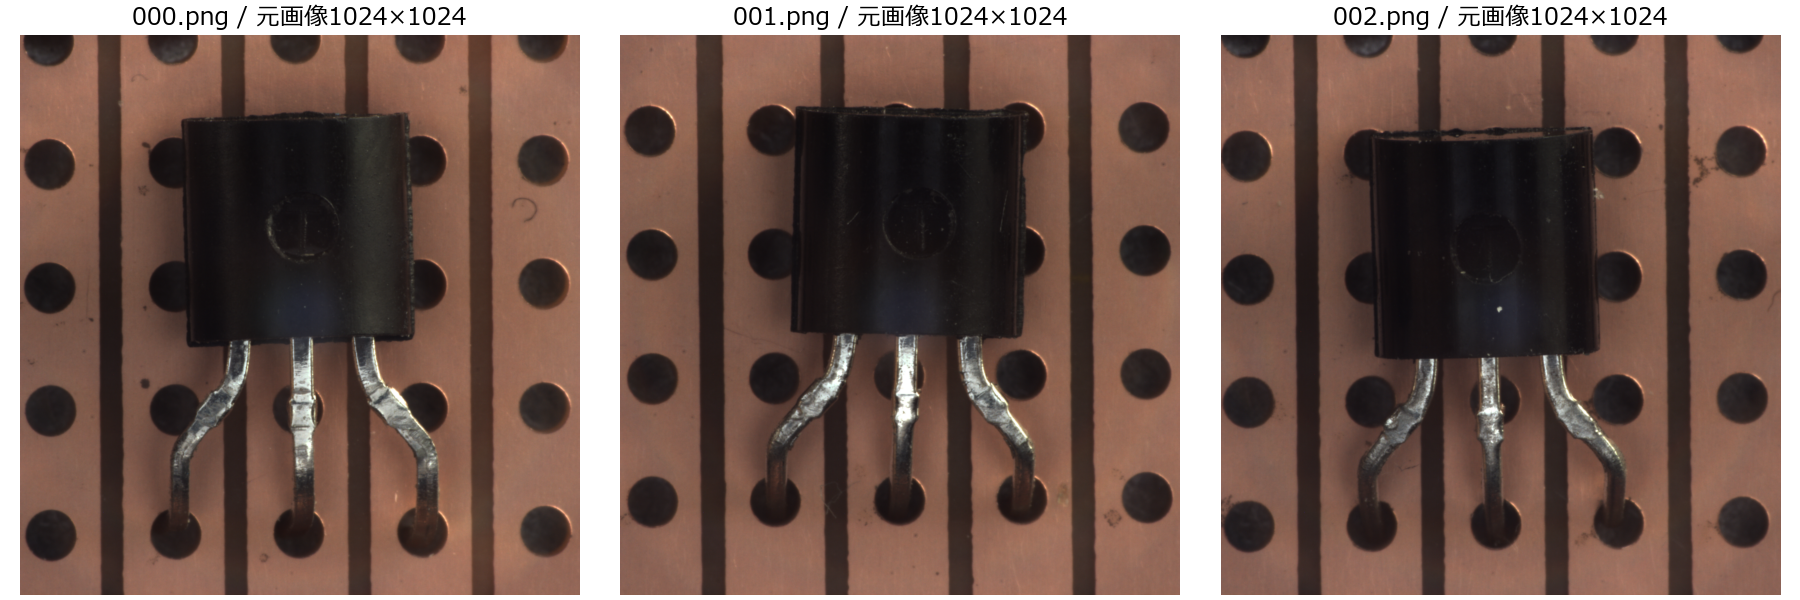

In [2]:
fig,axes=plt.subplots(1,len(source_names),figsize=(5*len(source_names),5),squeeze=False,constrained_layout=True)
for ax,name in zip(axes.flat,source_names):
    ax.imshow(images[name]);ax.set_title(f'{name} / 元画像1024×1024');ax.axis('off')
plt.show();plt.close(fig)

## 2. 同じ角度で比較する：最終128×128入力
上段edge／下段reflectです。橙色の枠は次の拡大図に対応する画像端です。角度・補間・縮小・白黒化は同じです。

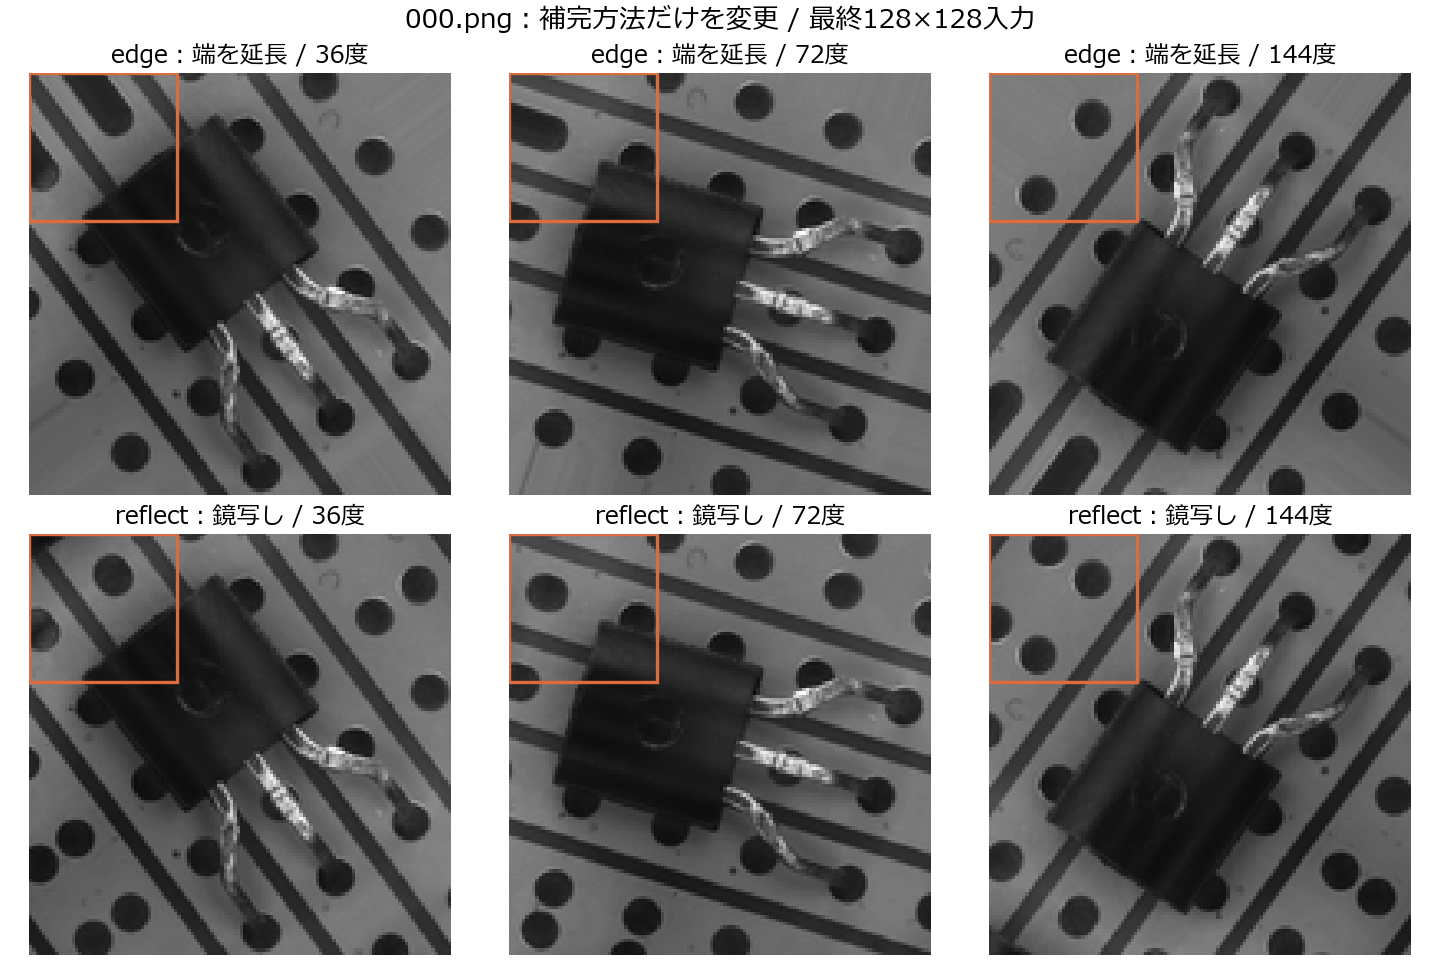

In [3]:
fig,axes=plt.subplots(2,len(COMPARE_ANGLES),figsize=(12,8),squeeze=False,constrained_layout=True)
for row,mode in enumerate(MODES):
    for col,angle in enumerate(COMPARE_ANGLES):
        show_input(axes[row,col],final_input(rotated(PRIMARY_IMAGE,angle,mode)[0]))
        draw_zoom_box(axes[row,col]);axes[row,col].set_title(f'{LABELS[mode]} / {angle}度')
fig.suptitle(f'{PRIMARY_IMAGE}：補完方法だけを変更 / 最終128×128入力',fontsize=16)
plt.show();plt.close(fig)

## 3. 画像端を拡大する：縮小前の高解像度画像
同じ1024×1024画像上の範囲を切り出して表示します。edgeの帯状の引き伸ばしと、reflectの折り返し・複製・境界を確認します。

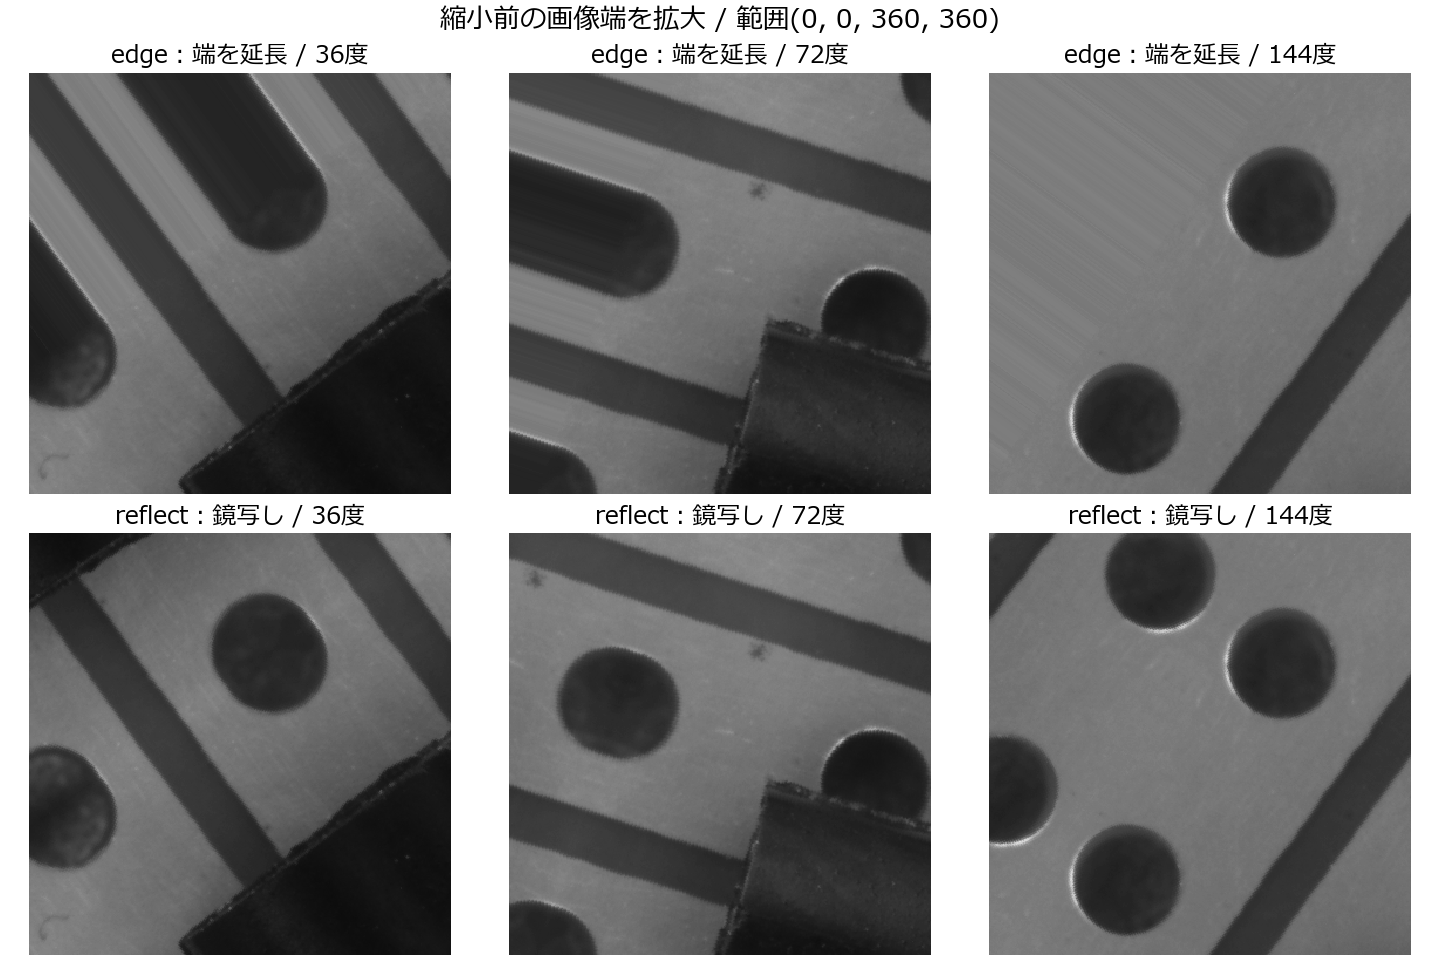

In [4]:
fig,axes=plt.subplots(2,len(COMPARE_ANGLES),figsize=(12,8),squeeze=False,constrained_layout=True)
for row,mode in enumerate(MODES):
    for col,angle in enumerate(COMPARE_ANGLES):
        im=rotated(PRIMARY_IMAGE,angle,mode)[0].crop(ZOOM_BOX).convert('L')
        axes[row,col].imshow(im,cmap='gray',vmin=0,vmax=255,interpolation='nearest');axes[row,col].axis('off')
        axes[row,col].set_title(f'{LABELS[mode]} / {angle}度')
fig.suptitle(f'縮小前の画像端を拡大 / 範囲{ZOOM_BOX}',fontsize=16)
plt.show();plt.close(fig)

## 4. 最終入力で画像端がどう見えるか
128×128に縮小した後、対応する範囲を拡大します。表示の補間はnearestに固定し、拡大表示で追加のぼかしを加えません。入力画像自体をさらに加工したものではありません。

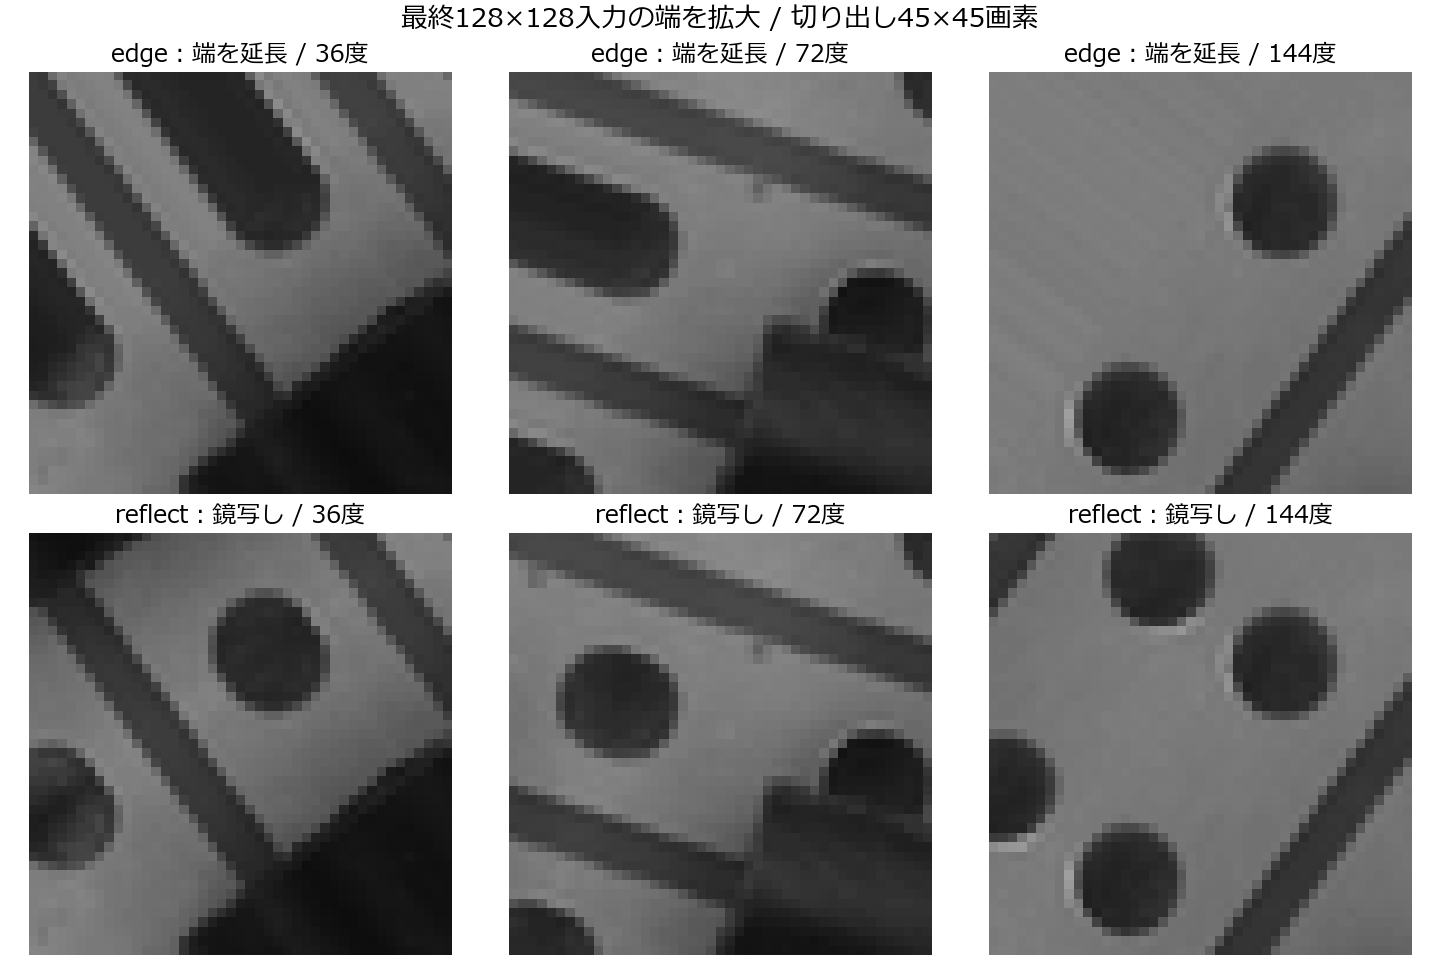

In [5]:
a,b,c,d=final_zoom_box()
fig,axes=plt.subplots(2,len(COMPARE_ANGLES),figsize=(12,8),squeeze=False,constrained_layout=True)
for row,mode in enumerate(MODES):
    for col,angle in enumerate(COMPARE_ANGLES):
        array=final_input(rotated(PRIMARY_IMAGE,angle,mode)[0])[b:d,a:c]
        show_input(axes[row,col],array);axes[row,col].set_title(f'{LABELS[mode]} / {angle}度')
fig.suptitle(f'最終128×128入力の端を拡大 / 切り出し{c-a}×{d-b}画素',fontsize=16)
plt.show();plt.close(fig)

## 5. どこが補完されたのか：領域マスクと方法間の画素差
上段は回転後1024×1024における元画像由来の領域（青緑）と補完領域（橙）です。マスクは画像の枠を回転して作り、被写体の正解マスクではありません。

下段はedgeとreflectのRGB画素差の最大値（0〜255）です。**画質や検出性能の良し悪しを表す指標ではありません。** 高解像度では元画像由来の画素が両方法で完全一致することを確認します。LANCZOS縮小後は、フィルタが境界をまたぐため、元画像領域側の境界近くにも違いが広がる場合があります。

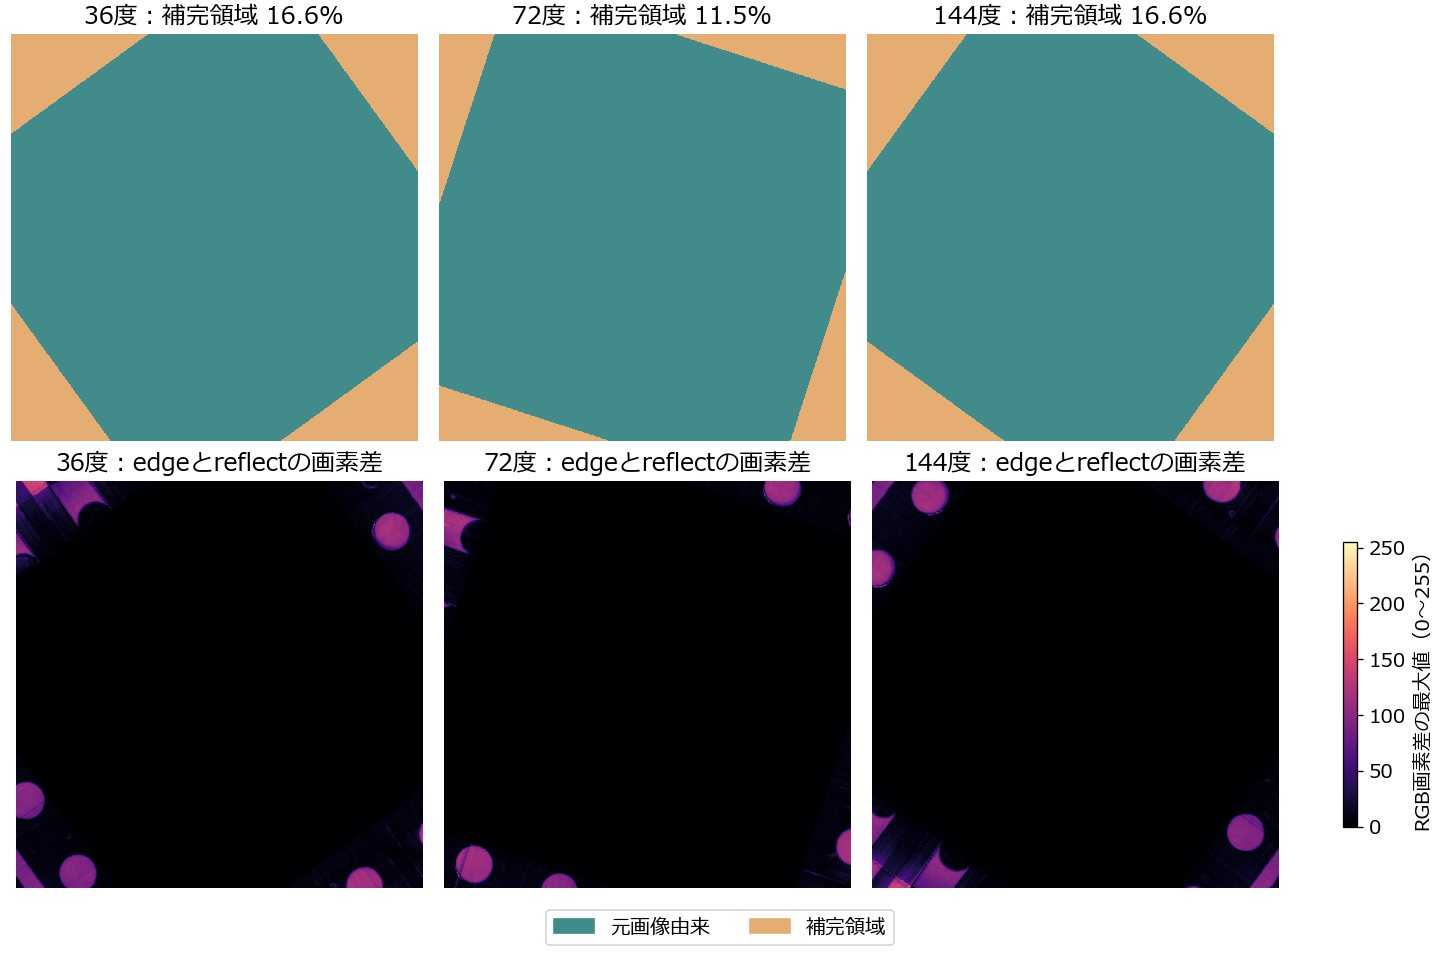

In [6]:
fig,axes=plt.subplots(2,len(COMPARE_ANGLES),figsize=(12,8),squeeze=False,constrained_layout=True)
mask_cmap=ListedColormap(['#e6ad72','#418b8b'])
for col,angle in enumerate(COMPARE_ANGLES):
    edge,mask=rotated(PRIMARY_IMAGE,angle,'edge');reflect,mask2=rotated(PRIMARY_IMAGE,angle,'reflect')
    assert np.array_equal(mask,mask2)
    pixels_edge=np.asarray(edge);pixels_reflect=np.asarray(reflect)
    assert np.array_equal(pixels_edge[mask],pixels_reflect[mask])
    difference=np.abs(pixels_edge.astype(np.int16)-pixels_reflect.astype(np.int16)).max(axis=2)
    assert np.all(difference[mask]==0)
    axes[0,col].imshow(mask,cmap=mask_cmap,vmin=0,vmax=1,interpolation='nearest');axes[0,col].set_title(f'{angle}度：補完領域 {100*(~mask).mean():.1f}%')
    heat=axes[1,col].imshow(difference,cmap='magma',vmin=0,vmax=255,interpolation='nearest')
    axes[1,col].set_title(f'{angle}度：edgeとreflectの画素差')
    for ax in axes[:,col]:ax.axis('off')
fig.legend(handles=[Patch(color='#418b8b',label='元画像由来'),Patch(color='#e6ad72',label='補完領域')],loc='lower center',ncol=2,bbox_to_anchor=(.5,.005))
fig.colorbar(heat,ax=axes[1,:],shrink=.7,label='RGB画素差の最大値（0〜255）')
fig.set_layout_engine('constrained',rect=(0,.07,1,.93))
plt.show();plt.close(fig)

## 6. 1枚から作る最終10方向：edgeとreflect
それぞれ0度を含む10枚です。0度は両方法とも通常入力と一致します。

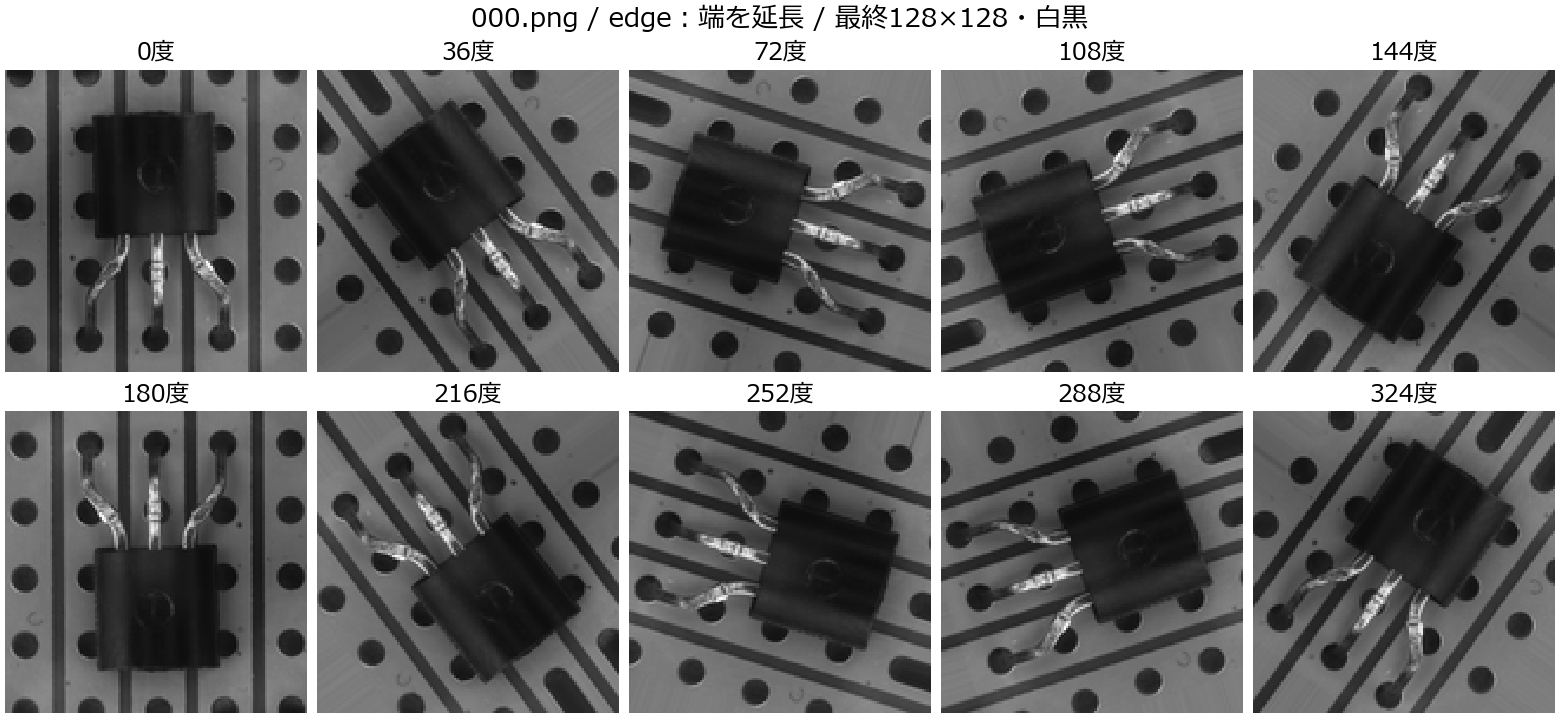

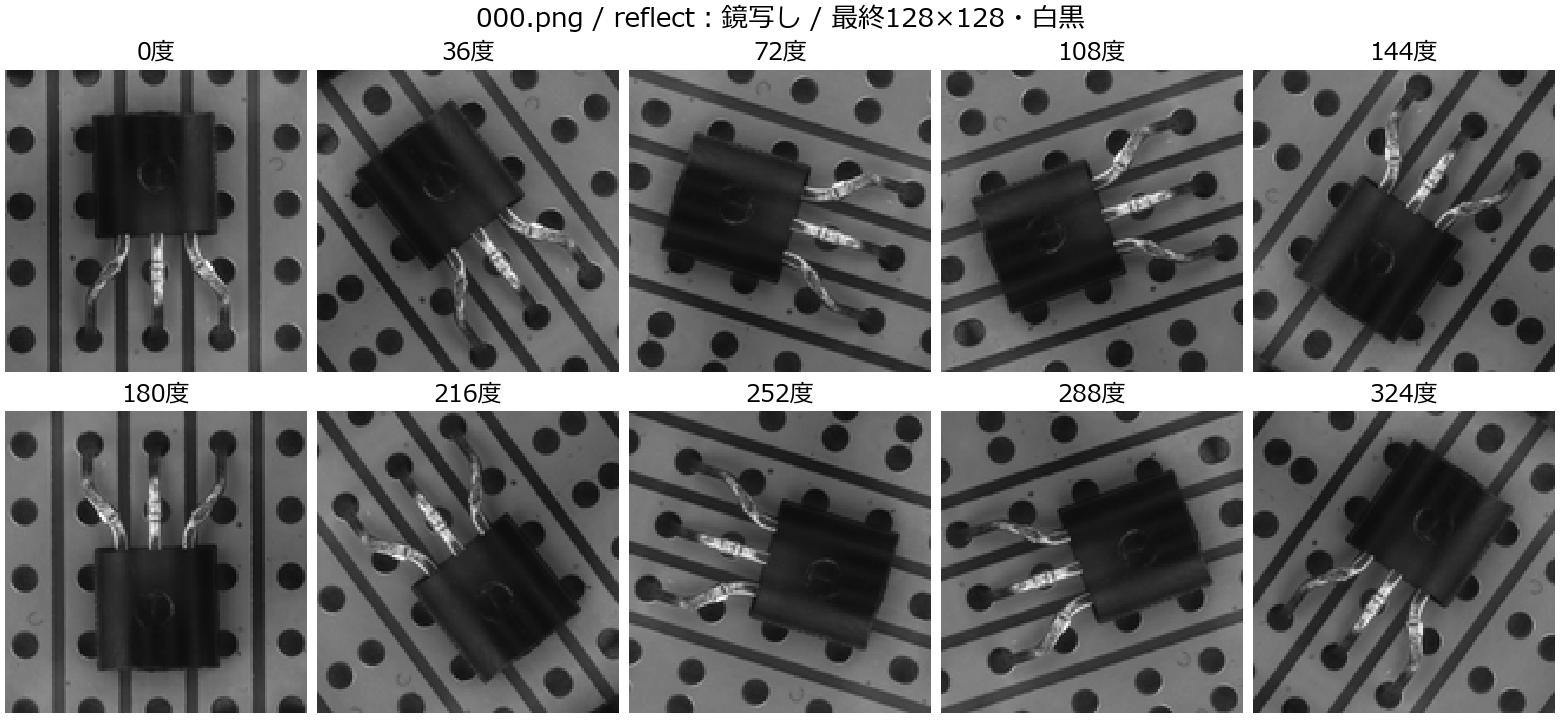

In [7]:
for mode in MODES:
    fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
    for ax,angle in zip(axes.flat,ANGLES):
        show_input(ax,final_input(rotated(PRIMARY_IMAGE,angle,mode)[0]));ax.set_title(f'{angle}度')
    fig.suptitle(f'{PRIMARY_IMAGE} / {LABELS[mode]} / 最終128×128・白黒',fontsize=16)
    plt.show();plt.close(fig)

## 7. 別の正常画像でも比較する
画像を替えたときにも、丸・線の伸び、折り返し、対象の複製や欠けが生じないか見比べます。元画像のファイル名は設定のSAMPLE_IMAGESで変更できます。

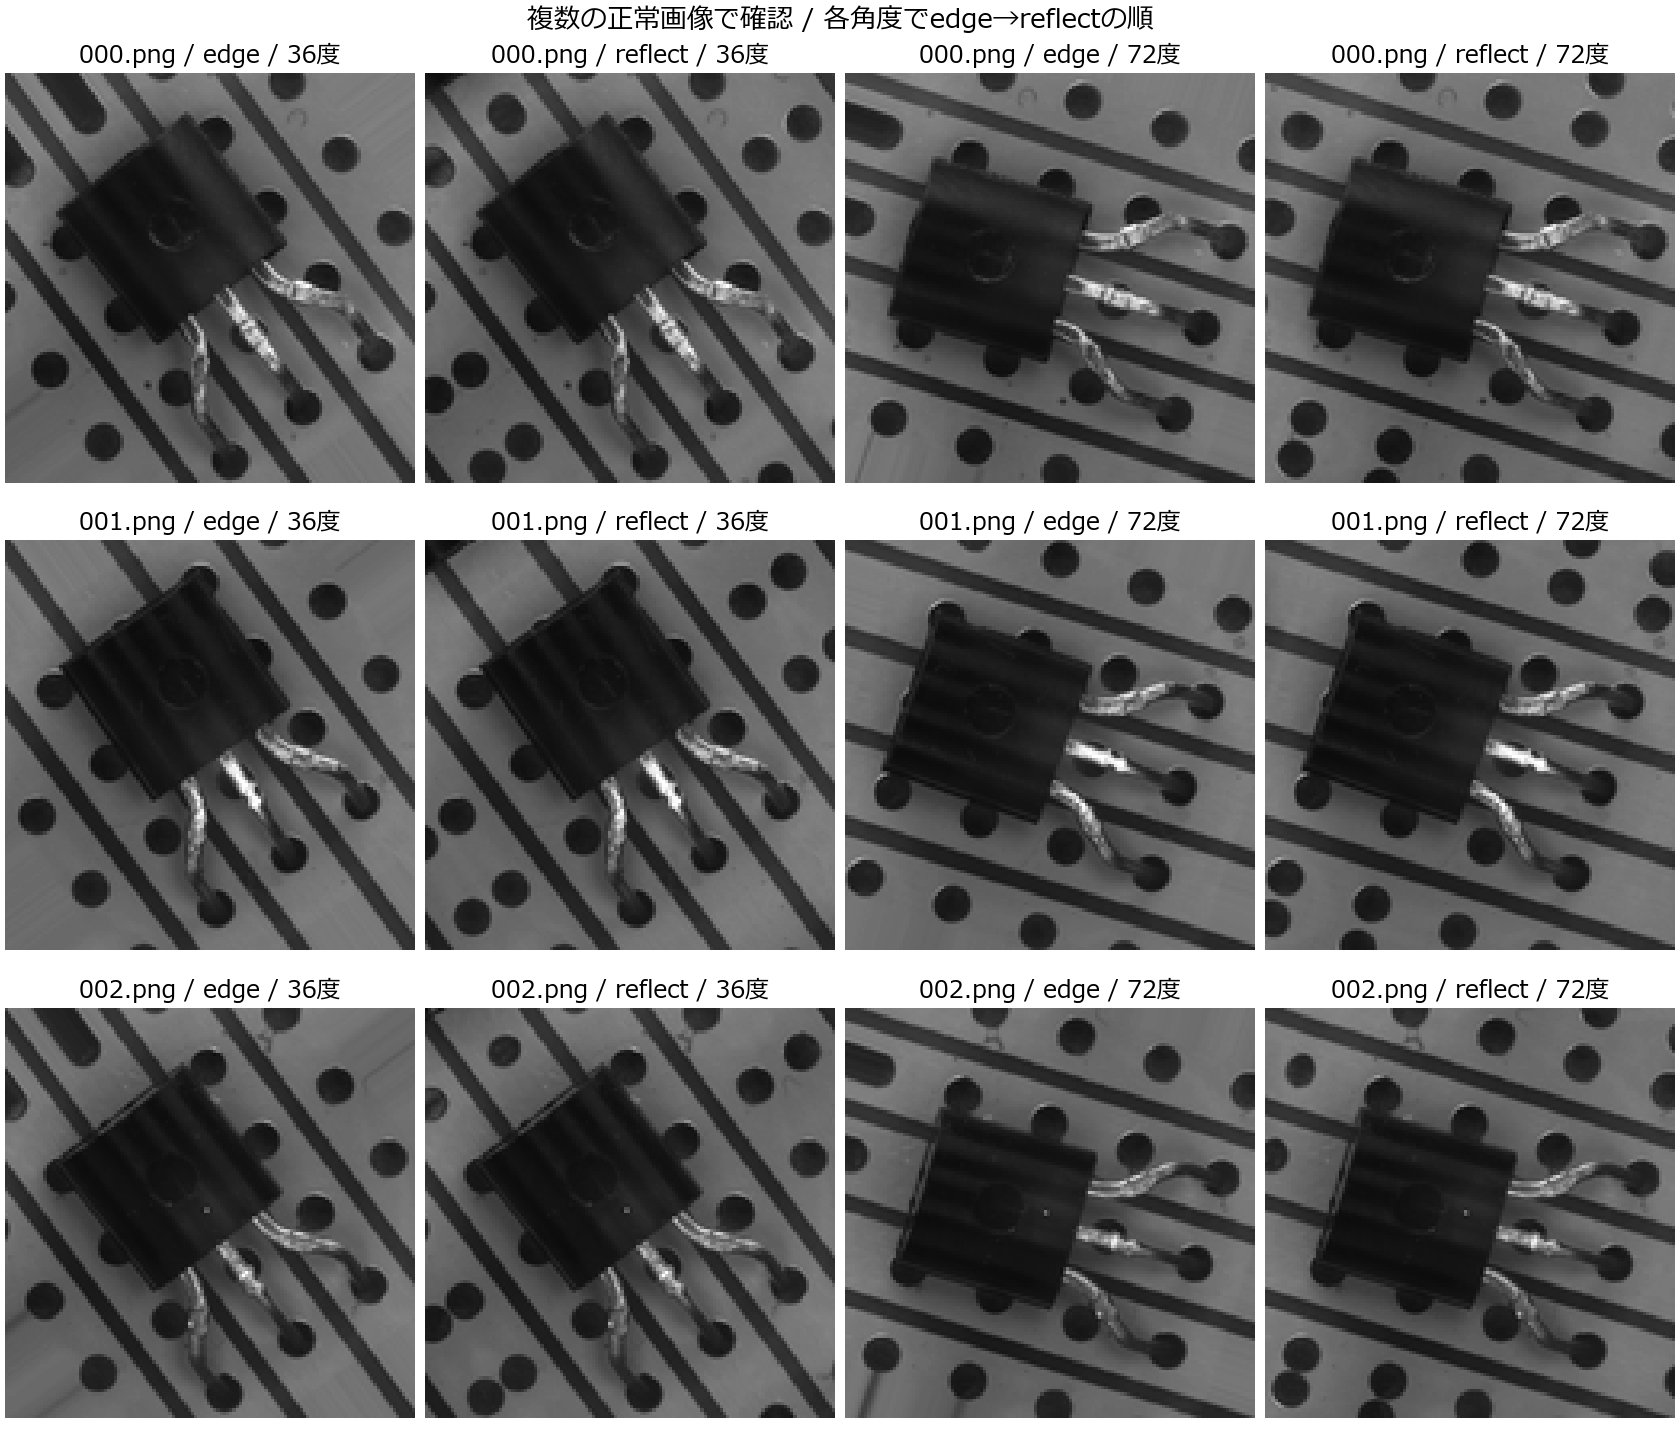

In [8]:
fig,axes=plt.subplots(len(SAMPLE_IMAGES),len(MULTI_ANGLES)*2,figsize=(14,4*len(SAMPLE_IMAGES)),squeeze=False,constrained_layout=True)
for row,name in enumerate(SAMPLE_IMAGES):
    for k,angle in enumerate(MULTI_ANGLES):
        for j,mode in enumerate(MODES):
            ax=axes[row,2*k+j];show_input(ax,final_input(rotated(name,angle,mode)[0]))
            ax.set_title(f'{name} / {mode} / {angle}度')
fig.suptitle('複数の正常画像で確認 / 各角度でedge→reflectの順',fontsize=16)
plt.show();plt.close(fig)

## 8. 計算と読み取り専用の確認
補完前の原画像を変えず、画像加工だけを行っていることを確認します。

In [9]:
for name in source_names:
    original=final_input(images[name])
    for mode in MODES:assert np.array_equal(final_input(rotated(name,0,mode)[0]),original)
    for angle in sorted(set(COMPARE_ANGLES+MULTI_ANGLES)):
        e,m=rotated(name,angle,'edge');r,m2=rotated(name,angle,'reflect')
        assert e.size==r.size==(1024,1024) and np.array_equal(m,m2)
        assert np.array_equal(np.asarray(e)[m],np.asarray(r)[m])
        for image in [e,r]:
            final=final_input(image)
            assert final.shape==(128,128) and final.dtype==np.float32
            assert np.isfinite(final).all() and 0<=final.min()<=final.max()<=1
    assert hashlib.sha256((TRAIN_DIR/name).read_bytes()).hexdigest()==source_hashes[name]
print('確認完了：0度入力一致／元画像領域一致／サイズ・値域／補完幅／元画像SHA-256不変')
print(json.dumps({'primary_image':PRIMARY_IMAGE,'sample_images':SAMPLE_IMAGES,'angles':ANGLES,
    'padding_modes':MODES,'pad_pixels':edge_pad_width((1024,1024)),
    'rotation_interpolation':'NEAREST','resize':'LANCZOS','output':[128,128],
    'source_sha256':source_hashes},ensure_ascii=False,indent=2))

確認完了：0度入力一致／元画像領域一致／サイズ・値域／補完幅／元画像SHA-256不変
{
  "primary_image": "000.png",
  "sample_images": [
    "000.png",
    "001.png",
    "002.png"
  ],
  "angles": [
    0,
    36,
    72,
    108,
    144,
    180,
    216,
    252,
    288,
    324
  ],
  "padding_modes": [
    "edge",
    "reflect"
  ],
  "pad_pixels": 217,
  "rotation_interpolation": "NEAREST",
  "resize": "LANCZOS",
  "output": [
    128,
    128
  ],
  "source_sha256": {
    "000.png": "d755cd3f9334acc338db228fbccfe531397add1794181c09dafafa35c9014741",
    "001.png": "479e538decadde0c2d687834e117a6e1a3002ece07d6b02ed145b1f116497e75",
    "002.png": "7e29cfe96f5183455a3f0298f4b29fd1879908887224cb79a2aab7bb102db828"
  }
}


## 見比べるときのポイント
- edgeの黒い丸が帯状に伸びる場所で、reflectにするとどう変わるか。
- reflectで丸がつながったり、対象の一部が複製されたりしていないか。
- 画像端だけでなく、補完領域と元画像領域の境界が不自然になっていないか。
- 回転後に本体や端子が画像枠から切れていないか。補完しても被写体全体が必ず残るわけではない。

この比較だけでreflectの採用やAUROC改善を決めず、複数画像の確認結果を基に次の実験条件を決めます。現在の学習用ノートブックはedgeのままです。

処理の参照：[現在のtransistor学習ノートブック](261105transistorの通常学習とedge回転拡張の比較学習とAUROC評価.ipynb)。補完仕様：[NumPy公式numpy.pad](https://numpy.org/doc/stable/reference/generated/numpy.pad.html)。